<a href="https://colab.research.google.com/github/yuvasrisugu2008-maker/ITA0515--COMPUTER-VISION/blob/main/exp%2029.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Libraries imported successfully!
OpenCV Version: 5.0.0


Saving pig.jpg to pig (5).jpg
Image uploaded successfully: pig (5).jpg


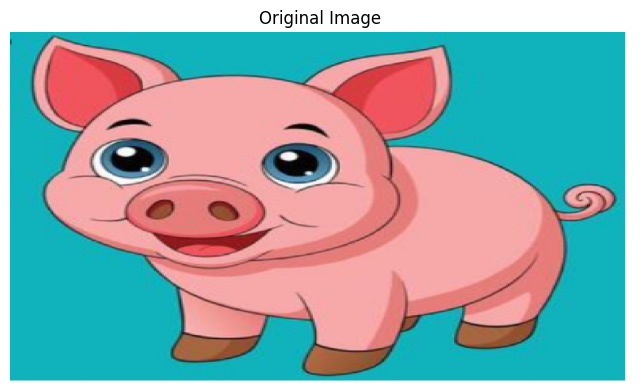

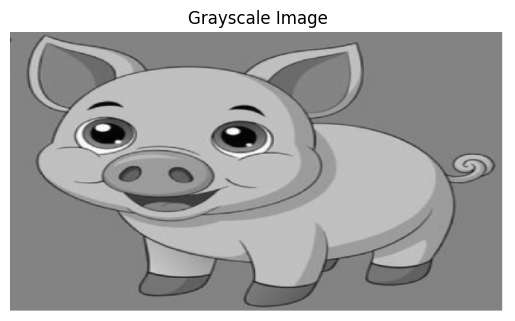

AttributeError: module 'cv2' has no attribute 'CascadeClassifier'

In [39]:
import cv2
import matplotlib.pyplot as plt
from google.colab import files

print("Libraries imported successfully!")
print("OpenCV Version:", cv2.__version__)
uploaded = files.upload()

filename = list(uploaded.keys())[0]

print("Image uploaded successfully:", filename)
# Read the uploaded image
img = cv2.imread(filename)

if img is None:
    raise ValueError("Unable to read the uploaded image.")

# Convert BGR to RGB
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Display original image
plt.figure(figsize=(8, 6))
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()
# Load eye detection classifier
eye_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades +
    "haarcascade_eye.xml"
)

# Check model
if eye_cascade.empty():
    raise ValueError("Eye detection model not loaded.")

print("Eye detection model loaded successfully!")
# Detect eyes in the grayscale image
eyes = eye_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(20, 20)
)

print("Number of eyes detected:", len(eyes))
# Create a copy of the original image
output = img.copy()

# Draw rectangles around detected eyes
for (x, y, w, h) in eyes:

    cv2.rectangle(
        output,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

    cv2.putText(
        output,
        "Eye",
        (x, max(y - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (0, 255, 0),
        2
    )

# Convert BGR to RGB
result = cv2.cvtColor(output, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 7))
plt.imshow(result)
plt.title("Human Eye Detection Result")
plt.axis("off")
plt.show()